# Higgs-pair production via gluon fusion: Standard Model and aligned two-Higgs-doublet model (A2HDM)

**Author:** Archana Gupta, Department of Physics, IIT (BHU), Varanasi  
**Version:** 1.0 (November 2026) · **Licence:** MIT · see `README.md` and `CITATION.cff` for how to cite

This notebook computes $pp \to hh$ through gluon fusion at the LHC at **leading order (LO) with the exact
top-quark mass dependence**, first in the Standard Model (SM) and then in the A2HDM, inside one workflow.

**What you get**
* the exact one-loop $gg\to hh$ amplitude (Glover–van der Bij; Plehn–Spira–Zerwas form factors), built from
  scalar one-loop integrals that the notebook evaluates itself, with no external Fortran library;
* a clean split into **triangle**, **box** and **resonant heavy-scalar** pieces, with every interference term kept;
* the hadronic cross section from a gluon–gluon PDF convolution, the $m_{hh}$ and $p_{T,h}$ distributions,
  SM and A2HDM benchmarks, the ratio $\sigma_{\rm A2HDM}/\sigma_{\rm SM}$, and validation tests.

**Run order:** top to bottom. The first full run takes a few minutes because the loop integrals are computed
numerically; they are cached and reused, so every later model costs seconds. Section 7 runs the SM test
first, and the A2HDM part starts only after the SM has been validated.

**Accuracy statement (read this first).** Everything here is LO QCD. NLO QCD with full top-mass dependence
raises the SM rate by a factor of about 1.7 and NNLO-improved predictions by about 1.9. Use the ratios
$\sigma_{\rm A2HDM}/\sigma_{\rm SM}$, which are far more stable, and do not quote the absolute LO numbers as predictions.

## 1. Physics introduction

### 1.1 Higgs-pair production in the SM
Producing two Higgs bosons is the most direct LHC handle on the Higgs self-coupling. After electroweak
symmetry breaking the SM potential contains the cubic term
$$ V \supset \lambda v\, h^3 = \frac{m_h^2}{2v} h^3 , \qquad g_{hhh}^{\rm SM} = \frac{3 m_h^2}{v}, $$
so a measurement of $hh$ production tests the shape of the Higgs potential itself.

### 1.2 Why gluon fusion dominates
The gluon density at the momentum fractions needed for $m_{hh}\gtrsim 250$ GeV is large, and the top quark
couples to the Higgs with strength $m_t/v\approx 1$. The loop-induced process $gg\to hh$ therefore gives
about 90% of the total $hh$ rate at 13 TeV, far above vector-boson fusion, $Vhh$ and $t\bar t hh$.

### 1.3 Triangle and box diagrams
At LO two classes of top-quark loops contribute:
* **Triangle:** $gg\to h^* \to hh$. A top triangle produces an off-shell Higgs that splits through $g_{hhh}$.
  It is suppressed at large $\hat s$ by the propagator $1/(\hat s-m_h^2)$ and is only spin-0.
* **Box:** the two Higgs bosons attach directly to the top loop, giving the coupling $y_t^2$. The box feeds
  both the spin-0 ($J_z=0$) and the spin-2 ($J_z=2$) gluon helicity states.

The triangle and the box interfere **destructively** in the spin-0 state. In the heavy-top limit they cancel
exactly at the threshold $\hat s = 4m_h^2$. This is why the SM rate is small and why it depends so strongly
on $g_{hhh}$. With full top-mass dependence the cancellation is partial, and the $m_{hh}$ spectrum peaks just
above the $t\bar t$ threshold $m_{hh}\simeq 2m_t$.

### 1.4 Higgs-pair production in the A2HDM
The A2HDM (Pich–Tuzón) has two doublets whose Yukawa matrices are **aligned** in flavour space,
$Y_{2,f} = \varsigma_f\, Y_{1,f}$, so there are no tree-level flavour-changing neutral currents. In the Higgs
basis ($\Phi_1$ carries the vacuum expectation value $v$) the physical scalars are $h$, $H$ (CP-even), $A$
(CP-odd) and $H^\pm$. Relative to the SM, $gg\to hh$ changes in three ways:
1. **Modified $h t\bar t$ coupling** $y_t^h = \cos\tilde\alpha + \varsigma_u \sin\tilde\alpha$. This rescales the
   box by $(y_t^h)^2$ and the $h$-triangle by $y_t^h$.
2. **Modified trilinear** $g_{hhh}$, fixed by the scalar potential parameters $\lambda_{1,6,345,7}$ and $\tilde\alpha$.
3. **A new s-channel triangle** $gg\to H^{(*)}\to hh$ with couplings $y_t^H g_{Hhh}$. For $m_H>2m_h$ this
   becomes a **resonance** in $m_{hh}$, which interferes with the box and with the $h$-triangle.

Box diagrams with the heavy scalars do not enter at LO, because the final state is two light $h$ bosons. The
pseudoscalar $A$ cannot decay to $hh$ when CP is conserved, so it does not contribute here.

### 1.5 CP assumption used here
**CP is conserved.** The alignment parameters $\varsigma_{u,d,\ell}$ are taken **real**, and the potential
couplings $\lambda_{5,6,7}$ are real. Complex alignment phases would give the $h t\bar t$ vertex a pseudoscalar
part and mix $A$ with $h,H$. That requires additional pseudoscalar box form factors, which are **not**
implemented, so the optional CP-violating benchmark is deliberately omitted. The code refuses complex inputs.

## 2. Setup
This cell installs one small package, `parton`, a pure-Python reader for LHAPDF grid files. Google Colab
already provides numpy, scipy, pandas and matplotlib.

In [1]:
# Install the LHAPDF-grid reader into the running kernel (works in Colab and in local Jupyter).
%pip install -q "parton==0.2.2"

In [2]:
# ---------------------------------------------------------------------------
# Imports and plotting style
# ---------------------------------------------------------------------------
import os, re, time, tarfile, urllib.request
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
import parton

plt.rcParams.update({
    "figure.figsize": (7.0, 4.6), "figure.dpi": 110, "font.size": 12,
    "axes.grid": True, "grid.alpha": 0.3, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})
np.set_printoptions(precision=5, suppress=True)

## 3. Inputs

### 3.1 SM and collider inputs
All masses are in GeV. The defaults match the setup of the full-$m_t$ LO and NLO calculations of
Borowka et al. (arXiv:1604.06447, 1608.04798): $m_h=125$ GeV, $m_t=173$ GeV, $\sqrt s=13$ TeV,
$\mu_R=\mu_F=m_{hh}/2$. That allows a literature check of the SM number in Section 4.

* **PDFs:** `PDF4LHC21_40` (current PDF4LHC recommendation) is the default. The literature check also downloads
  `PDF4LHC15_nlo_100_pdfas`, the set used by Borowka et al.
* **$\alpha_s(\mu_R)$** is read from the $\alpha_s$ grid stored in the PDF set, as LHAPDF does.
* **Bottom quark:** it is included in the triangle diagrams of every scalar. Its box contribution is
  suppressed by $m_b^2/\hat s$ and is neglected.

In [3]:
# ---------------------------------------------------------------------------
# SM, collider and numerical inputs (edit here; nothing else needs to change)
# ---------------------------------------------------------------------------
SM = dict(
    mh=125.0,          # Higgs mass [GeV]
    mt=173.0,          # top-quark pole mass used in the loops [GeV]
    mb=4.75,           # bottom-quark pole mass used in the triangle loops [GeV]
    mb_run=2.75,       # approximate running b mass at ~300-500 GeV, used only in H -> b bbar widths [GeV]
    mtau=1.77686,      # tau mass [GeV]
    mW=80.369,         # W mass [GeV]
    mZ=91.1876,        # Z mass [GeV]
    GF=1.1663787e-5,   # Fermi constant [GeV^-2]
    Gamma_h=4.1e-3,    # SM Higgs width [GeV]; enters only the far off-shell h* propagator
)
SM["v"] = (np.sqrt(2.0) * SM["GF"]) ** -0.5      # vacuum expectation value, about 246.22 GeV

COLLIDER = dict(
    sqrts=13000.0,          # proton-proton centre-of-mass energy [GeV]
    pdf_set="PDF4LHC21_40", # LHAPDF set name (downloaded automatically)
    mu_over_mhh=0.5,        # mu_R = mu_F = mu_over_mhh * m_hh
)

NUM = dict(
    n_cos=12,              # Gauss-Legendre nodes in cos(theta) on (0,1); the integrand is even in cos(theta)
    n_mhh=8,               # Gauss-Legendre nodes per m_hh segment
    mhh_max=2000.0,        # upper limit of the m_hh integration [GeV]
    nodes_low=24,          # Feynman-parameter nodes per dimension away from the top threshold
    nodes_high=32,         # ... for s/mt^2 > 15 (m_hh above ~670 GeV)
    nodes_thr=40,          # ... within thr_refine GeV of the top threshold
    thr_refine=15.0,       # [GeV]
    thr_window=(-1.0, 7.0),# m_hh - 2 m_t window [GeV] where box form factors are interpolated, not computed
    lam0=1.5,              # contour-deformation strength (dimensionless)
    g_fit_cos=0.8,         # spin-2 form factor: nodes with |cos| above this are replaced by the sin^2 fit
)
GEV2_TO_FB = 0.3893794e12  # 1 GeV^-2 = 0.3893794 mb = 0.3893794e12 fb

### 3.2 PDF download, $\alpha_s$ and the gluon–gluon luminosity
The hadronic cross section is
$$ \sigma(pp\to hh) = \int_{4m_h^2/S}^{1} d\tau\; \frac{d\mathcal L_{gg}}{d\tau}(\tau,\mu_F)\;
   \hat\sigma_{gg\to hh}(\hat s=\tau S,\mu_R), \qquad
   \frac{d\mathcal L_{gg}}{d\tau} = \int_\tau^1 \frac{dx}{x}\, g(x,\mu_F)\, g(\tau/x,\mu_F). $$
Changing variables to $m_{hh}=\sqrt{\tau S}$ gives $d\sigma/dm_{hh} = (2m_{hh}/S)\,(d\mathcal L/d\tau)\,\hat\sigma$.
The $x$ integral uses $x=\tau^y$, which flattens the $1/x$ behaviour, followed by Gauss–Legendre quadrature in $y$.

In [4]:
# ---------------------------------------------------------------------------
# PDF handling: download an LHAPDF set, read alpha_s from its .info file,
# and build the gluon-gluon luminosity dL/dtau.
# ---------------------------------------------------------------------------
PDF_DIR = os.path.abspath("pdfsets")
os.makedirs(PDF_DIR, exist_ok=True)

def get_pdf_set(name):
    """Download and unpack an LHAPDF set from the official CERN mirror (once)."""
    target = os.path.join(PDF_DIR, name)
    if not os.path.isdir(target):
        url = f"https://lhapdfsets.web.cern.ch/current/{name}.tar.gz"
        tgz = os.path.join(PDF_DIR, name + ".tar.gz")
        print(f"downloading {url} ...")
        urllib.request.urlretrieve(url, tgz)
        with tarfile.open(tgz) as tf:
            tf.extractall(PDF_DIR)
        os.remove(tgz)
    return target

class PDFSet:
    """Central member of an LHAPDF set: gluon density and alpha_s(Q).

    alpha_s is interpolated (cubic, in log Q) from the AlphaS_Qs/AlphaS_Vals grid stored in the
    set's .info file, which is what LHAPDF itself does for these sets."""
    def __init__(self, name):
        get_pdf_set(name)
        self.name = name
        self.pdf = parton.mkPDF(name, 0, pdfdir=PDF_DIR)
        info = open(os.path.join(PDF_DIR, name, name + ".info")).read()
        def read_list(key):
            m = re.search(key + r":\s*\[([^\]]*)\]", info, re.S)
            return np.array([float(x) for x in m.group(1).replace("\n", " ").split(",") if x.strip()])
        qs, vals = read_list("AlphaS_Qs"), read_list("AlphaS_Vals")
        qs, idx = np.unique(qs, return_index=True)          # drop duplicated flavour-threshold nodes
        self._as = CubicSpline(np.log(qs), vals[idx])
        self.alphas_mz = self.alphas(SM["mZ"])

    def alphas(self, Q):
        return float(self._as(np.log(Q)))

    def gluon(self, x, Q):
        """g(x,Q) (number density, not x*g)."""
        return self.pdf.xfxQ2(21, x, Q**2, grid=False) / x

    def lumi_gg(self, tau, Q, n=96):
        """dL_gg/dtau at scale Q, using x = tau**y and Gauss-Legendre in y."""
        y, w = np.polynomial.legendre.leggauss(n)
        y, w = 0.5 * (y + 1.0), 0.5 * w
        x1 = tau ** y
        return -np.log(tau) * np.sum(w * self.gluon(x1, Q) * self.gluon(tau / x1, Q))

PDF = PDFSet(COLLIDER["pdf_set"])
print(f"{PDF.name}: alpha_s(MZ) = {PDF.alphas_mz:.4f},  alpha_s(200 GeV) = {PDF.alphas(200.0):.4f}")

PDF4LHC21_40: alpha_s(MZ) = 0.1180,  alpha_s(200 GeV) = 0.1055


## 4. The $gg\to hh$ amplitude

### 4.1 Structure (analytic ingredients)
With gluon colours $a,b$ and polarisations $\epsilon_{1,2}$, the LO amplitude is (Plehn, Spira, Zerwas,
hep-ph/9603205, Nucl. Phys. B479 (1996) 46)
$$ \mathcal M = \frac{G_F\,\alpha_s\,\hat s}{2\sqrt2\,\pi}\,\delta^{ab}\,\epsilon_{1\mu}\epsilon_{2\nu}
   \Big[ \big(C_\triangle F_\triangle + C_\Box F_\Box\big) A_1^{\mu\nu} + C_\Box G_\Box A_2^{\mu\nu} \Big], $$
where $A_1$ projects on the spin-0 and $A_2$ on the spin-2 gluon state ($A_1\!\cdot\!A_2=0$). The partonic
cross section is
$$ \frac{d\hat\sigma}{d\hat t} = \frac{G_F^2\alpha_s^2(\mu_R)}{512\,(2\pi)^3}
   \Big[\, \big|C_\triangle F_\triangle + C_\Box F_\Box\big|^2 + \big|C_\Box G_\Box\big|^2 \,\Big]. $$
The spin-0 bracket contains the **triangle–box interference** $2\,{\rm Re}(C_\triangle F_\triangle\, C_\Box^* F_\Box^*)$.
The spin-2 term has no triangle, because an s-channel scalar is spin-0.

**Coefficients.** In the SM, $C_\Box = 1$ and $C_\triangle = g_{hhh}v/(\hat s-m_h^2+im_h\Gamma_h) = 3m_h^2/(\hat s - m_h^2 + \dots)$.
In general, with quark loops $q=t,b$ and s-channel scalars $\phi = h, H$:
$$ C_\triangle F_\triangle \;\to\; \sum_{\phi}\frac{g_{\phi hh}\,v}{\hat s - m_\phi^2 + i m_\phi\Gamma_\phi}
   \sum_q y_q^\phi\, F_\triangle(\hat s/m_q^2), \qquad C_\Box \to (y_t^h)^2 . $$

**Form factors** (dimensionless; $S=\hat s/m_t^2$, $T=\hat t/m_t^2$, $U=\hat u/m_t^2$, $\rho=m_h^2/m_t^2$,
$T_1=T-\rho$, $U_1=U-\rho$; all $C_{ij}$, $D_{ijk}$ are scalar integrals in units of $m_t$):
$$ F_\triangle = \frac{2}{S}\big[2 + (4-S)\, C_{ab}\big] $$
$$ F_\Box = \frac{1}{S^2}\Big\{ 4S + 8S C_{ab} - 2S(S+2\rho-8)(D_{abc}+D_{bac}+D_{acb})
  + (2\rho-8)\big[T_1C_{ac}+U_1C_{bc}+U_1C_{ad}+T_1C_{bd} - (TU-\rho^2)D_{acb}\big]\Big\} $$
$$ G_\Box = \frac{1}{S(TU-\rho^2)}\Big\{ (T^2+\rho^2-8T)\big[SC_{ab}+T_1C_{ac}+T_1C_{bd}-STD_{bac}\big]
  + (U^2+\rho^2-8U)\big[SC_{ab}+U_1C_{bc}+U_1C_{ad}-SUD_{abc}\big]
  - (T^2+U^2-2\rho^2)(T+U-8)C_{cd} - 2(T+U-8)(TU-\rho^2)(D_{abc}+D_{bac}+D_{acb})\Big\} $$
Heavy-top limit: $F_\triangle\to 2/3$, $F_\Box\to-2/3$, $G_\Box\to 0$. Section 5 checks this numerically.

**Scalar integrals.** $C_{ab}=C_0(0,0,\hat s)$, $C_{ac}=C_{bd}=C_0(0,m_h^2,\hat t)$, $C_{bc}=C_{ad}=C_0(0,m_h^2,\hat u)$,
$C_{cd}=C_0(m_h^2,m_h^2,\hat s)$, $D_{abc}=D_0(0,0,m_h^2,m_h^2;\hat s,\hat u)$, $D_{bac}=D_0(0,0,m_h^2,m_h^2;\hat s,\hat t)$,
$D_{acb}=D_0(0,m_h^2,0,m_h^2;\hat t,\hat u)$, all with four (or three) internal top propagators and LoopTools
normalisation $\int d^4q/(i\pi^2)$.

### 4.2 Numerical strategy (what is exact and what is numerical)
* **Exact closed forms:** every $C_0$ with a massless leg,
  $C_0(0,0,s) = \frac{1}{2s}\big[\ln\frac{1+\beta}{1-\beta}-i\pi\big]^2$ above threshold (with $-\frac{2}{s}\arcsin^2\sqrt{s/4m^2}$ below it),
  and $C_0(0,p^2,q^2) = [g(p^2)-g(q^2)]/(p^2-q^2)$ with $g(s)=s\,C_0(0,0,s)$.
* **Numerical:** $C_{cd}$ and the three boxes. They are integrated in Feynman-parameter space after a
  *primary sector decomposition* and a *contour deformation* $x_k\to x_k - i\lambda x_k(1-x_k)\,\partial_k\Delta$,
  the method used by SecDec and pySecDec. The deformation implements the $-i0$ prescription above the
  $t\bar t$ threshold. Each Feynman-parameter dimension uses tensor Gauss–Legendre quadrature.
* **Threshold treatment:** at exactly $m_{hh}=2m_t$ the integrands have a Landau singularity, and the
  quadrature converges slowly in a few-GeV window. Box form factors are therefore linearly interpolated
  across $m_{hh}-2m_t \in [-1,+7]$ GeV. The window contributes about 1% of $\sigma$, and the interpolation error is well below that.
* **Spin-2 form factor:** angular momentum forces $G_\Box\propto\sin^2\theta$ as $\theta\to0$, while the formula
  divides by $TU-\rho^2\propto p_T^2$. The resulting forward cancellation is regularised by fitting
  $G_\Box=(1-\cos^2\theta)\,(a+b\cos^2\theta+c\cos^4\theta)$ on the central nodes and using the fit for $|\cos\theta|>0.8$.

In [5]:
# ---------------------------------------------------------------------------
# 4.2a  Scalar one-loop integrals with equal internal masses (units: m = 1)
# ---------------------------------------------------------------------------
def _gl_tensor(n, dim):
    """Tensor-product Gauss-Legendre rule on [0,1]^dim: nodes (M, dim) and weights (M,)."""
    x, w = np.polynomial.legendre.leggauss(n)
    x, w = 0.5 * (x + 1.0), 0.5 * w
    nodes = np.array(list(product(x, repeat=dim)))
    weights = np.prod(np.array(list(product(w, repeat=dim))), axis=1)
    return nodes, weights

_GL_CACHE = {}
def gl_tensor(n, dim):
    if (n, dim) not in _GL_CACHE:
        _GL_CACHE[(n, dim)] = _gl_tensor(n, dim)
    return _GL_CACHE[(n, dim)]

def loop_integral_numeric(ext, kind, n_nodes=24, lam0=1.5, chunk=48):
    """Scalar C0 (kind='C', 3 propagators) or D0 (kind='D', 4 propagators), all internal masses = 1.

    ext[k, i, j] = (r_i - r_j)^2 for propagator momenta r_i (units m^2), for a batch of K kinematic points.
    Representation (Delta = 1/2 x^T Y x - i0, Y_ij = 2 - (r_i - r_j)^2):
        D0 =  int_simplex 1/Delta^2,           C0 = - int_simplex 1/((sum x) Delta)   (projective form)
    Primary sectors: x_l = 1, other x in [0,1]. Contour deformation: z = t - i lam t(1-t) dDelta/dt."""
    Y = 2.0 - np.asarray(ext, dtype=float)
    K, N, _ = Y.shape
    t, w = gl_tensor(n_nodes, N - 1)
    M = t.shape[0]
    lam_all = lam0 / (1.0 + np.max(np.abs(Y), axis=(1, 2)))     # deformation scaled to the kinematics
    out = np.zeros(K, dtype=complex)
    idx = np.arange(N - 1)
    with np.errstate(all="ignore"):
        for k0 in range(0, K, chunk):
            Yc = Y[k0:k0 + chunk]
            kc = Yc.shape[0]
            lam = lam_all[k0:k0 + chunk][:, None, None]
            acc = np.zeros(kc, dtype=complex)
            for l in range(N):                                    # primary sector l: x_l is the largest
                free = [i for i in range(N) if i != l]
                x = np.ones((M, N)); x[:, free] = t
                grad = np.einsum("kij,mj->kmi", Yc, x)[:, :, free]  # dDelta/dt on the real contour
                tt = t[None, :, :]
                z = np.ones((kc, M, N), dtype=complex)
                z[:, :, free] = tt - 1j * lam * tt * (1 - tt) * grad
                Delta = 0.5 * np.einsum("kmi,kij,kmj->km", z, Yc, z)
                J = np.zeros((kc, M, N - 1, N - 1), dtype=complex)   # Jacobian dz/dt
                J[:, :, idx, idx] = 1.0 - 1j * lam * (1 - 2 * tt) * grad
                Yff = Yc[:, free][:, :, free]
                J -= 1j * lam[..., None] * (tt * (1 - tt))[..., None] * Yff[:, None, :, :]
                detJ = np.linalg.det(J)
                f = detJ / Delta**2 if kind == "D" else -detJ / (np.sum(z, axis=2) * Delta)
                acc += f @ w
            out[k0:k0 + chunk] = acc
    return out

def c0_00s(S):
    """Exact C0(0,0,s; m,m,m) * m^2 for real S = s/m^2 (+i0 prescription)."""
    S = np.atleast_1d(np.asarray(S, dtype=float))
    out = np.empty(S.shape, dtype=complex)
    tiny = np.abs(S) < 1e-9
    neg, mid, big = (S < 0) & ~tiny, (S >= 0) & (S < 4) & ~tiny, S >= 4
    out[tiny] = -0.5
    out[neg] = 2.0 / S[neg] * np.arcsinh(np.sqrt(-S[neg]) / 2.0) ** 2
    out[mid] = -2.0 / S[mid] * np.arcsin(np.sqrt(S[mid] / 4.0)) ** 2
    b = np.sqrt(1.0 - 4.0 / S[big])
    out[big] = (np.log((1 + b) / (1 - b)) - 1j * np.pi) ** 2 / (2.0 * S[big])
    return out

def c0_0pq(P, Q):
    """Exact C0(0,p^2,q^2; m,m,m) * m^2 = [g(P) - g(Q)]/(P - Q),  g(s) = s C0(0,0,s)."""
    P, Q = np.broadcast_arrays(np.atleast_1d(P).astype(float), np.atleast_1d(Q).astype(float))
    return (P * c0_00s(P) - Q * c0_00s(Q)) / (P - Q)

def ext_C(p1, p2, s):
    """(r_i - r_j)^2 matrix for C0(p1^2, p2^2, s)."""
    p1, p2, s = np.broadcast_arrays(*map(np.atleast_1d, (p1, p2, s)))
    e = np.zeros((len(s), 3, 3))
    e[:, 0, 1] = e[:, 1, 0] = p1; e[:, 1, 2] = e[:, 2, 1] = p2; e[:, 0, 2] = e[:, 2, 0] = s
    return e

def ext_D(p1, p2, p3, p4, s12, s23):
    """(r_i - r_j)^2 matrix for D0(p1^2,p2^2,p3^2,p4^2; s12, s23)."""
    p1, p2, p3, p4, s12, s23 = np.broadcast_arrays(*map(np.atleast_1d, (p1, p2, p3, p4, s12, s23)))
    e = np.zeros((len(s12), 4, 4))
    for (i, j), val in {(0, 1): p1, (1, 2): p2, (2, 3): p3, (0, 3): p4, (0, 2): s12, (1, 3): s23}.items():
        e[:, i, j] = e[:, j, i] = val
    return e

In [6]:
# ---------------------------------------------------------------------------
# 4.2b  Plehn-Spira-Zerwas form factors
# ---------------------------------------------------------------------------
def F_triangle(S):
    """Triangle form factor F_tri(S = s/mq^2) for one quark flavour (exact, analytic). -> 2/3 for mq -> inf."""
    S = np.atleast_1d(np.asarray(S, dtype=float))
    return 2.0 / S * (2.0 + (4.0 - S) * c0_00s(S))

def box_form_factors(S, T, rho, n_nodes=24, lam0=1.5):
    """Top-loop box form factors F_box (spin 0) and G_box (spin 2) at fixed S for an array of T values."""
    T = np.atleast_1d(np.asarray(T, dtype=float))
    S = np.full_like(T, S)
    U = 2.0 * rho - S - T
    T1, U1 = T - rho, U - rho
    Cab = c0_00s(S)
    Cac = c0_0pq(rho, T); Cbd = Cac                    # C0(0, mh^2, t)
    Cbc = c0_0pq(rho, U); Cad = Cbc                    # C0(0, mh^2, u)
    Ccd = loop_integral_numeric(ext_C(rho, rho, S), "C", n_nodes=max(n_nodes, 48), lam0=lam0)
    Dabc = loop_integral_numeric(ext_D(0, 0, rho, rho, S, U), "D", n_nodes, lam0)
    Dbac = loop_integral_numeric(ext_D(0, 0, rho, rho, S, T), "D", n_nodes, lam0)
    Dacb = loop_integral_numeric(ext_D(0, rho, 0, rho, T, U), "D", n_nodes, lam0)
    Dsum = Dabc + Dbac + Dacb
    Fbox = (4 * S + 8 * S * Cab - 2 * S * (S + 2 * rho - 8) * Dsum
            + (2 * rho - 8) * (T1 * Cac + U1 * Cbc + U1 * Cad + T1 * Cbd - (T * U - rho**2) * Dacb)) / S**2
    Gbox = ((T**2 + rho**2 - 8 * T) * (S * Cab + T1 * Cac + T1 * Cbd - S * T * Dbac)
            + (U**2 + rho**2 - 8 * U) * (S * Cab + U1 * Cbc + U1 * Cad - S * U * Dabc)
            - (T**2 + U**2 - 2 * rho**2) * (T + U - 8) * Ccd
            - 2 * (T + U - 8) * (T * U - rho**2) * Dsum) / (S * (T * U - rho**2))
    return Fbox, Gbox

In [7]:
# ---------------------------------------------------------------------------
# 4.2c  Cached table of box form factors on the (m_hh, cos theta) grid.
#       The box form factors depend only on SM masses, never on the A2HDM parameters,
#       so they are computed once and reused for every model and benchmark.
# ---------------------------------------------------------------------------
_cx, _cw = np.polynomial.legendre.leggauss(2 * NUM["n_cos"])
COS_NODES, COS_WEIGHTS = _cx[NUM["n_cos"]:], _cw[NUM["n_cos"]:]   # nodes in (0,1)
_BOX_CACHE = {}

def _mandelstam_T(mhh, cos):
    """T = t/mt^2 for given m_hh and scattering angle."""
    mt, mh = SM["mt"], SM["mh"]
    S, rho = (mhh / mt) ** 2, (mh / mt) ** 2
    beta = np.sqrt(1.0 - 4.0 * rho / S)
    return S, rho, rho - 0.5 * S * (1.0 - beta * cos)

def _regularise_G(G, cos):
    """Replace forward nodes of G_box by the fit (1-c^2)(a + b c^2 + c c^4) to the central nodes."""
    sel = cos <= NUM["g_fit_cos"]
    A = (1 - cos[sel] ** 2)[:, None] * np.vander(cos[sel] ** 2, 3, increasing=True)
    coef, *_ = np.linalg.lstsq(A.astype(complex), G[sel], rcond=None)
    Gfit = (1 - cos**2) * (np.vander(cos**2, 3, increasing=True) @ coef)
    return np.where(sel, G, Gfit)

def _box_direct(mhh):
    S, rho, T = _mandelstam_T(mhh, COS_NODES)
    if abs(mhh - 2 * SM["mt"]) < NUM["thr_refine"]:
        n = NUM["nodes_thr"]
    else:
        n = NUM["nodes_low"] if S < 15 else NUM["nodes_high"]
    Fb, Gb = box_form_factors(S, T, rho, n_nodes=n, lam0=NUM["lam0"])
    return Fb, _regularise_G(Gb, COS_NODES)

def box_ff(mhh):
    """(F_box, G_box) at the cos-theta nodes for this m_hh, with caching and the threshold window."""
    key = round(float(mhh), 6)
    if key in _BOX_CACHE:
        return _BOX_CACHE[key]
    lo, hi = 2 * SM["mt"] + NUM["thr_window"][0], 2 * SM["mt"] + NUM["thr_window"][1]
    if lo < mhh < hi:                                   # threshold window: linear interpolation
        Flo, Glo = box_ff(lo); Fhi, Ghi = box_ff(hi)
        a = (mhh - lo) / (hi - lo)
        res = ((1 - a) * Flo + a * Fhi, (1 - a) * Glo + a * Ghi)
    else:
        res = _box_direct(mhh)
    if not (np.all(np.isfinite(res[0])) and np.all(np.isfinite(res[1]))):
        raise FloatingPointError(f"non-finite box form factor at m_hh = {mhh}")
    _BOX_CACHE[key] = res
    return res

### 4.3 Model layer: one interface for the SM and the A2HDM
A *model* is a small dictionary holding everything the amplitude needs:
* `yt_h`: the $h t\bar t$ coupling relative to the SM, which sets the box coefficient $(y_t^h)^2$;
* `scalars`: a list of s-channel scalars $\phi$, each with mass, width, $g_{\phi hh}$ [GeV], $y_t^\phi$ and $y_b^\phi$.

The SM is just one entry ($\phi = h$, $g_{hhh}=3m_h^2/v$, $y=1$). The A2HDM adds $H$. The cross-section code
never needs to know which model it is running.

In [8]:
# ---------------------------------------------------------------------------
# 4.3  Model definitions and the amplitude split into triangle / box / spin-2 pieces
# ---------------------------------------------------------------------------
def sm_model(kappa_lambda=1.0, kappa_t=1.0, name="SM"):
    """SM (kappa_lambda = kappa_t = 1) or the usual kappa-framework rescaling of it."""
    mh, v = SM["mh"], SM["v"]
    return dict(name=name, yt_h=kappa_t,
                scalars=[dict(name="h", m=mh, Gamma=SM["Gamma_h"], g=kappa_lambda * 3 * mh**2 / v,
                              yt=kappa_t, yb=1.0)])

def amplitude_pieces(mhh, model):
    """Spin-0 triangle amplitude per scalar, spin-0 box and spin-2 box at the cos-theta nodes.

    Returns dict: 'tri' -> {phi: array}, 'box' -> array, 'G' -> array (all dimensionless, PSZ normalisation)."""
    s = mhh**2
    Fbox, Gbox = box_ff(mhh)
    Ft_top = F_triangle(s / SM["mt"] ** 2)[0]
    Ft_bot = F_triangle(s / SM["mb"] ** 2)[0]
    tri = {}
    for sc in model["scalars"]:
        prop = sc["g"] * SM["v"] / (s - sc["m"] ** 2 + 1j * sc["m"] * sc["Gamma"])
        tri[sc["name"]] = prop * (sc["yt"] * Ft_top + sc["yb"] * Ft_bot) * np.ones_like(COS_NODES)
    yt2 = model["yt_h"] ** 2
    return dict(tri=tri, box=yt2 * Fbox, G=yt2 * Gbox)

def matrix_element_terms(pieces):
    """|M|^2 split into named pieces (arrays over cos nodes). The total is the plain sum of all terms."""
    tri, box, G = pieces["tri"], pieces["box"], pieces["G"]
    names = list(tri)
    terms = {"box (spin 0)": np.abs(box) ** 2, "box (spin 2)": np.abs(G) ** 2}
    for n in names:
        terms[f"triangle {n}"] = np.abs(tri[n]) ** 2
        terms[f"interf. box x tri {n}"] = 2 * np.real(box * np.conj(tri[n]))
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            terms[f"interf. tri {a} x tri {b}"] = 2 * np.real(tri[a] * np.conj(tri[b]))
    return terms

## 5. Cross section: partonic integration and PDF convolution

For each $m_{hh}$ the angular integral uses $d\hat t = (\hat s\beta/2)\,d\cos\theta$, $\beta=\sqrt{1-4m_h^2/\hat s}$.
The integrand is even in $\cos\theta$, so nodes are placed in $(0,1)$ and the result is doubled. The
$m_{hh}$ integral runs over Gauss–Legendre segments whose edges sit at the physical features: the $hh$
threshold, the $t\bar t$ threshold window, and $m_\phi\pm k\Gamma_\phi$ around any heavy-scalar resonance.

In [9]:
# ---------------------------------------------------------------------------
# 5.  Partonic cross section, hadronic integration and the m_hh grid
# ---------------------------------------------------------------------------
def mhh_segments(model):
    """Segment edges for the m_hh integral, adapted to thresholds and resonances of this model."""
    mh, mt = SM["mh"], SM["mt"]
    lo_w, hi_w = 2 * mt + NUM["thr_window"][0], 2 * mt + NUM["thr_window"][1]
    edges = {2 * mh + 1e-3, 270.0, 300.0, 325.0, lo_w, hi_w, 2 * mt + NUM["thr_refine"],
             400.0, 450.0, 550.0, 700.0, 900.0, 1200.0, 1600.0, NUM["mhh_max"]}
    for sc in model["scalars"]:
        couples = abs(sc["g"]) > 0 and (abs(sc["yt"]) + abs(sc["yb"])) > 0
        if sc["m"] > 2 * mh and couples:                # resonant heavy scalar: refine around the peak
            for k in (0.3, 1, 3, 10, 30, 100):
                edges.update({sc["m"] - k * sc["Gamma"], sc["m"] + k * sc["Gamma"]})
    edges = np.array(sorted(e for e in edges if 2 * mh < e <= NUM["mhh_max"]))
    keep = np.concatenate(([True], np.diff(edges) > 1e-3))
    return edges[keep]

def mhh_quadrature(model):
    """Gauss-Legendre nodes and weights in m_hh for this model."""
    x, w = np.polynomial.legendre.leggauss(NUM["n_mhh"])
    edges = mhh_segments(model)
    nodes = np.concatenate([0.5 * (b - a) * x + 0.5 * (a + b) for a, b in zip(edges[:-1], edges[1:])])
    weights = np.concatenate([0.5 * (b - a) * w for a, b in zip(edges[:-1], edges[1:])])
    return nodes, weights

def dsigma_dmhh_terms(mhh, model, pdf=None):
    """d sigma / d m_hh [fb/GeV], split into |M|^2 terms (same keys as matrix_element_terms)."""
    pdf = pdf or PDF
    s, mh = mhh**2, SM["mh"]
    beta = np.sqrt(1.0 - 4.0 * mh**2 / s)
    mu = COLLIDER["mu_over_mhh"] * mhh
    a_s = pdf.alphas(mu)
    pref = SM["GF"] ** 2 * a_s**2 / (512.0 * (2 * np.pi) ** 3) * (s * beta / 2.0) * 2.0   # dt and cos -> (-1,1)
    lum = 2.0 * mhh / COLLIDER["sqrts"] ** 2 * pdf.lumi_gg(s / COLLIDER["sqrts"] ** 2, mu)
    terms = matrix_element_terms(amplitude_pieces(mhh, model))
    return {k: pref * lum * np.sum(COS_WEIGHTS * v) * GEV2_TO_FB for k, v in terms.items()}

def cross_section(model, pdf=None, verbose=True):
    """Total LO sigma(pp -> hh) [fb], its decomposition, and the m_hh distribution on the quadrature nodes."""
    t0 = time.time()
    nodes, weights = mhh_quadrature(model)
    rows = [dsigma_dmhh_terms(m, model, pdf) for m in nodes]
    keys = list(rows[0])
    dist = {k: np.array([r[k] for r in rows]) for k in keys}
    parts = {k: float(np.sum(weights * dist[k])) for k in keys}
    total = float(sum(parts.values()))
    if verbose:
        print(f"{model['name']:>12s}: sigma_LO = {total:8.3f} fb   ({len(nodes)} m_hh nodes, {time.time()-t0:.0f} s)")
    return dict(model=model["name"], sigma=total, parts=parts, mhh=nodes, w=weights,
                dist=dist, dsig=sum(dist.values()))

## 6. Validation of the loop engine (before any physics run)
Three checks of the numerical integrals, each printed with an explicit PASS or FAIL:
1. the numerical $C_0$ against the exact $C_0(0,0,\hat s)$ and $C_0(0,m_h^2,\hat t)$, below and above threshold;
2. the heavy-top limit $F_\triangle\to2/3$, $F_\Box\to-2/3$, $G_\Box\to0$, which tests the form-factor algebra;
3. independence of the result from the contour-deformation strength $\lambda$, which tests the $-i0$ continuation.

In [10]:
# ---------------------------------------------------------------------------
# 6.  Engine validation
# ---------------------------------------------------------------------------
def check(label, ok, detail=""):
    print(f"[{'PASS' if ok else 'FAIL'}] {label} {detail}")
    return ok

ALL_CHECKS = []
rho0 = (SM["mh"] / SM["mt"]) ** 2

# (1) numerical C0 versus exact formulas
for S in (2.0, 5.35, 12.0):
    num = loop_integral_numeric(ext_C(0.0, 0.0, S), "C", n_nodes=40)[0]
    ana = c0_00s(S)[0]
    ALL_CHECKS.append(check(f"C0(0,0,s) at s/mt^2={S}", abs(num - ana) / abs(ana) < 1e-4,
                            f"rel. diff {abs(num-ana)/abs(ana):.1e}"))
for T in (-0.5, -5.0):
    num = loop_integral_numeric(ext_C(0.0, rho0, T), "C", n_nodes=40)[0]
    ana = c0_0pq(rho0, T)[0]
    ALL_CHECKS.append(check(f"C0(0,mh^2,t) at t/mt^2={T}", abs(num - ana) / abs(ana) < 1e-6,
                            f"rel. diff {abs(num-ana)/abs(ana):.1e}"))

# (2) heavy-quark limit of the form factors (quark mass 20 TeV, m_hh = 400 GeV)
mq = 20000.0
S_h, rho_h = (400.0 / mq) ** 2, (SM["mh"] / mq) ** 2
T_h = rho_h - 0.5 * S_h * (1 - np.sqrt(1 - 4 * rho_h / S_h) * 0.5)
Fb_h, Gb_h = box_form_factors(S_h, T_h, rho_h)
Ft_h = F_triangle(S_h)[0]
ALL_CHECKS.append(check("heavy-top limit F_tri -> 2/3", abs(Ft_h - 2/3) < 1e-4, f"F_tri = {Ft_h.real:.5f}"))
ALL_CHECKS.append(check("heavy-top limit F_box -> -2/3", abs(Fb_h[0] + 2/3) < 1e-4, f"F_box = {Fb_h[0].real:.5f}"))
ALL_CHECKS.append(check("heavy-top limit G_box -> 0", abs(Gb_h[0]) < 1e-4, f"|G_box| = {abs(Gb_h[0]):.1e}"))

# (3) contour-deformation independence above the ttbar threshold (m_hh = 450 GeV)
S_d, rho_d, T_d = _mandelstam_T(450.0, np.array([0.3, 0.7]))
ref = box_form_factors(S_d, T_d, rho_d, n_nodes=32, lam0=1.5)
alt = box_form_factors(S_d, T_d, rho_d, n_nodes=32, lam0=0.9)
dev = max(np.max(np.abs(ref[0] - alt[0])), np.max(np.abs(ref[1] - alt[1])))
ALL_CHECKS.append(check("deformation independence (lambda 1.5 vs 0.9)", dev < 1e-5, f"max |diff| = {dev:.1e}"))

[PASS] C0(0,0,s) at s/mt^2=2.0 rel. diff 3.0e-15
[PASS] C0(0,0,s) at s/mt^2=5.35 rel. diff 1.3e-15
[PASS] C0(0,0,s) at s/mt^2=12.0 rel. diff 1.6e-10
[PASS] C0(0,mh^2,t) at t/mt^2=-0.5 rel. diff 4.0e-15
[PASS] C0(0,mh^2,t) at t/mt^2=-5.0 rel. diff 4.8e-15
[PASS] heavy-top limit F_tri -> 2/3 F_tri = 0.66668
[PASS] heavy-top limit F_box -> -2/3 F_box = -0.66668
[PASS] heavy-top limit G_box -> 0 |G_box| = 5.6e-06


[PASS] deformation independence (lambda 1.5 vs 0.9) max |diff| = 1.9e-06


## 7. SM test run
The SM is computed first. The checks are against the published LO full-$m_t$ result (Borowka et al.,
JHEP 10 (2016) 107): $\sigma_{\rm LO}=16.72$ fb at 13 TeV with `PDF4LHC15_nlo_100_pdfas`, $m_t=173$ GeV,
$\mu=m_{hh}/2$. The first call computes and caches all box form factors, which takes a few minutes.

In [11]:
# ---------------------------------------------------------------------------
# 7.  SM run (default PDF set) and literature check (PDF set used in the literature)
# ---------------------------------------------------------------------------
res_SM = cross_section(sm_model())
for k, v in res_SM["parts"].items():
    print(f"   {k:<28s} {v:9.3f} fb")

PDF_LIT = PDFSet("PDF4LHC15_nlo_100_pdfas")
res_SM_lit = cross_section(sm_model(name="SM (PDF4LHC15)"), pdf=PDF_LIT)
ALL_CHECKS.append(check("SM LO vs Borowka et al. 16.72 fb (within 2%)",
                        abs(res_SM_lit["sigma"] / 16.72 - 1) < 0.02, f"this notebook: {res_SM_lit['sigma']:.2f} fb"))
ALL_CHECKS.append(check("triangle-box interference is negative (destructive) in the SM",
                        res_SM["parts"]["interf. box x tri h"] < 0,
                        f"interference = {res_SM['parts']['interf. box x tri h']:.2f} fb"))
ALL_CHECKS.append(check("sum of the decomposition equals the total",
                        abs(sum(res_SM["parts"].values()) - res_SM["sigma"]) < 1e-9 * res_SM["sigma"]))

          SM: sigma_LO =   16.514 fb   (112 m_hh nodes, 139 s)
   box (spin 0)                    33.761 fb
   box (spin 2)                     0.594 fb
   triangle h                       4.528 fb
   interf. box x tri h            -22.369 fb
SM (PDF4LHC15): sigma_LO =   16.790 fb   (112 m_hh nodes, 0 s)
[PASS] SM LO vs Borowka et al. 16.72 fb (within 2%) this notebook: 16.79 fb
[PASS] triangle-box interference is negative (destructive) in the SM interference = -22.37 fb
[PASS] sum of the decomposition equals the total 


### 7.1 Self-coupling scan (interference test)
Because the triangle scales with $\kappa_\lambda$ and interferes with the box, $\sigma(\kappa_\lambda)$ is an exact
parabola $A + B\kappa_\lambda + C\kappa_\lambda^2$. Its minimum lies near $\kappa_\lambda\approx 2.4$, and
$\sigma(\kappa_\lambda=0)/\sigma_{\rm SM}\approx 2$ to $2.3$. Both depend on the interference having the right sign and
size. All box form factors are already cached, so the scan takes seconds.

In [12]:
kl_values = np.linspace(-2, 6, 17)
sig_kl = np.array([cross_section(sm_model(kappa_lambda=k, name=f"kl={k:+.1f}"), verbose=False)["sigma"]
                   for k in kl_values])
C2, C1, C0_ = np.polyfit(kl_values, sig_kl, 2)
kl_min = -C1 / (2 * C2)
print(f"sigma(kl) = {C0_:.2f} {C1:+.2f} kl {C2:+.3f} kl^2  [fb];  minimum at kl = {kl_min:.2f}")
print(f"sigma(kl=0)/sigma_SM = {np.interp(0, kl_values, sig_kl)/res_SM['sigma']:.2f}")
ALL_CHECKS.append(check("kappa_lambda minimum in [2.2, 2.6]", 2.2 < kl_min < 2.6, f"(kl_min = {kl_min:.2f})"))
ALL_CHECKS.append(check("sigma(kl) is an exact parabola",
                        np.max(np.abs(np.polyval([C2, C1, C0_], kl_values) - sig_kl)) < 1e-6 * res_SM["sigma"]))

sigma(kl) = 34.35 -22.37 kl +4.528 kl^2  [fb];  minimum at kl = 2.47
sigma(kl=0)/sigma_SM = 2.08
[PASS] kappa_lambda minimum in [2.2, 2.6] (kl_min = 2.47)
[PASS] sigma(kl) is an exact parabola 


## 8. The A2HDM

### 8.1 Scalar potential and conventions (Higgs basis, CP conserved)
$$ V = \mu_1\Phi_1^\dagger\Phi_1+\mu_2\Phi_2^\dagger\Phi_2 + \big[\mu_3\Phi_1^\dagger\Phi_2+{\rm h.c.}\big]
 + \tfrac{\lambda_1}{2}(\Phi_1^\dagger\Phi_1)^2 + \tfrac{\lambda_2}{2}(\Phi_2^\dagger\Phi_2)^2
 + \lambda_3(\Phi_1^\dagger\Phi_1)(\Phi_2^\dagger\Phi_2) + \lambda_4(\Phi_1^\dagger\Phi_2)(\Phi_2^\dagger\Phi_1)
 + \Big[\big(\tfrac{\lambda_5}{2}\Phi_1^\dagger\Phi_2 + \lambda_6\Phi_1^\dagger\Phi_1 + \lambda_7\Phi_2^\dagger\Phi_2\big)\Phi_1^\dagger\Phi_2 + {\rm h.c.}\Big] $$
with $\langle\Phi_1^0\rangle=v/\sqrt2$, $\langle\Phi_2\rangle=0$, and all $\lambda_i$ real. The CP-even states are
$$ h = \cos\tilde\alpha\, S_1 + \sin\tilde\alpha\, S_2,\qquad H = -\sin\tilde\alpha\, S_1 + \cos\tilde\alpha\, S_2 , $$
so $\tilde\alpha\to0$ is the **alignment limit**, where $h$ is exactly SM-like.

**Inputs:** $m_H, m_A, m_{H^\pm}, \sin\tilde\alpha, \lambda_2, \lambda_3, \lambda_7, \varsigma_u, \varsigma_d, \varsigma_\ell$.
**Derived quantities:**
$\lambda_1 v^2 = c^2m_h^2+s^2m_H^2$, $\lambda_6 v^2 = cs\,(m_h^2-m_H^2)$, $\lambda_5 v^2 = s^2m_h^2+c^2m_H^2-m_A^2$,
$\lambda_4 = \lambda_5 + 2(m_A^2-m_{H^\pm}^2)/v^2$, $\mu_2 = m_{H^\pm}^2-\lambda_3v^2/2$,
with $c=\cos\tilde\alpha$ and $s=\sin\tilde\alpha$.

**Couplings entering $gg\to hh$:**
* Yukawas, normalised to the SM: $y_f^h = c + \varsigma_f\, s$, $y_f^H = -s + \varsigma_f\, c$. Gauge: $\kappa_V^h=c$, $\kappa_V^H=-s$.
* Cubic terms: $V_3 = \frac v2\big[\lambda_1S_1^3 + 3\lambda_6S_1^2S_2 + \lambda_{345}S_1S_2^2 + \lambda_7S_2^3\big]$, with $\lambda_{345}=\lambda_3+\lambda_4+\lambda_5$.
  Rotating gives $g_{hhh}=6\,[h^3]$ and $g_{Hhh}=2\,[Hh^2]$, normalised so that $g_{hhh}^{\rm SM}=3m_h^2/v$.

### 8.2 The heavy-scalar width
$\Gamma_H$ enters the resonant propagator. It is computed at LO from the open channels
$H\to t\bar t, b\bar b, \tau\tau, WW, ZZ, hh, gg$. If $H\to AA, H^+H^-, ZA, W^\pm H^\mp$ is kinematically open,
the width would be incomplete, so the filter rejects the point.

In [13]:
# ---------------------------------------------------------------------------
# 8.  A2HDM: parameters, derived potential couplings, physical couplings, H width
# ---------------------------------------------------------------------------
def a2hdm_point(name, mH, mA, mHc, sin_alpha, lam2, lam3, lam7, zeta_u, zeta_d=0.0, zeta_l=0.0):
    """Collect one A2HDM input point. CP is conserved: all inputs must be real."""
    p = dict(name=name, mH=mH, mA=mA, mHc=mHc, sin_alpha=sin_alpha, lam2=lam2, lam3=lam3, lam7=lam7,
             zeta_u=zeta_u, zeta_d=zeta_d, zeta_l=zeta_l)
    for k, val in p.items():
        if k != "name" and np.iscomplexobj(val):
            raise ValueError(f"{k} is complex: CP-violating alignment phases are not implemented")
    return p

def a2hdm_lambdas(p):
    """Higgs-basis quartic couplings and mu2 derived from the physical inputs."""
    mh, v = SM["mh"], SM["v"]
    s = p["sin_alpha"]; c = np.sqrt(1 - s**2)
    lam1 = (c**2 * mh**2 + s**2 * p["mH"] ** 2) / v**2
    lam6 = c * s * (mh**2 - p["mH"] ** 2) / v**2
    lam5 = (s**2 * mh**2 + c**2 * p["mH"] ** 2 - p["mA"] ** 2) / v**2
    lam4 = lam5 + 2 * (p["mA"] ** 2 - p["mHc"] ** 2) / v**2
    mu2 = p["mHc"] ** 2 - p["lam3"] * v**2 / 2
    return dict(lam1=lam1, lam2=p["lam2"], lam3=p["lam3"], lam4=lam4, lam5=lam5, lam6=lam6, lam7=p["lam7"],
                mu2=mu2, c=c, s=s)

def a2hdm_trilinears(p):
    """g_hhh and g_Hhh [GeV] in the normalisation g_hhh(SM) = 3 mh^2/v."""
    L = a2hdm_lambdas(p); v = SM["v"]; c, s = L["c"], L["s"]
    l345 = L["lam3"] + L["lam4"] + L["lam5"]
    c_hhh = v / 2 * (L["lam1"] * c**3 + 3 * L["lam6"] * c**2 * s + l345 * c * s**2 + L["lam7"] * s**3)
    c_Hhh = v / 2 * (L["lam1"] * (-3 * c**2 * s) + 3 * L["lam6"] * (c**3 - 2 * c * s**2)
                     + l345 * (2 * s * c**2 - s**3) + L["lam7"] * 3 * s**2 * c)
    return 6 * c_hhh, 2 * c_Hhh

def a2hdm_couplings(p):
    """All couplings relevant here, normalised to the SM where applicable."""
    L = a2hdm_lambdas(p); c, s = L["c"], L["s"]
    g_hhh, g_Hhh = a2hdm_trilinears(p)
    y = lambda zeta: (c + zeta * s, -s + zeta * c)          # (y^h, y^H)
    yt, yb, yl = y(p["zeta_u"]), y(p["zeta_d"]), y(p["zeta_l"])
    return dict(yt_h=yt[0], yt_H=yt[1], yb_h=yb[0], yb_H=yb[1], ytau_h=yl[0], ytau_H=yl[1],
                kV_h=c, kV_H=-s, g_hhh=g_hhh, g_Hhh=g_Hhh,
                kappa_lambda=g_hhh / (3 * SM["mh"] ** 2 / SM["v"]))

def _A_half(tau):
    """Spin-1/2 loop function for H -> gg, normalised to 4/3 in the heavy-quark limit; tau = mH^2/(4 mq^2)."""
    if tau <= 1:
        f = np.arcsin(np.sqrt(tau)) ** 2
    else:
        b = np.sqrt(1 - 1 / tau)
        f = -0.25 * (np.log((1 + b) / (1 - b)) - 1j * np.pi) ** 2
    return 2 * (tau + (tau - 1) * f) / tau**2

def width_H(p, pdf=None):
    """LO partial widths of H [GeV] for the channels included here."""
    pdf = pdf or PDF
    C = a2hdm_couplings(p); mH = p["mH"]; GF = SM["GF"]
    out = {}
    def ff(mf, nc, y):
        if mH <= 2 * mf: return 0.0
        b = np.sqrt(1 - 4 * mf**2 / mH**2)
        return nc * GF * mH * mf**2 / (4 * np.sqrt(2) * np.pi) * y**2 * b**3
    def vv(mV, delta, k):
        x = mV**2 / mH**2
        if x >= 0.25: return 0.0
        return delta * GF * mH**3 / (16 * np.sqrt(2) * np.pi) * k**2 * np.sqrt(1 - 4 * x) * (1 - 4 * x + 12 * x**2)
    out["tt"] = ff(SM["mt"], 3, C["yt_H"])
    out["bb"] = ff(SM["mb_run"], 3, C["yb_H"])
    out["tautau"] = ff(SM["mtau"], 1, C["ytau_H"])
    out["WW"] = vv(SM["mW"], 2, C["kV_H"])
    out["ZZ"] = vv(SM["mZ"], 1, C["kV_H"])
    out["hh"] = (C["g_Hhh"] ** 2 / (32 * np.pi * mH) * np.sqrt(1 - 4 * SM["mh"] ** 2 / mH**2)
                 if mH > 2 * SM["mh"] else 0.0)
    amp = sum(y * 0.75 * _A_half(mH**2 / (4 * mq**2)) for y, mq in ((C["yt_H"], SM["mt"]), (C["yb_H"], SM["mb"])))
    out["gg"] = GF * pdf.alphas(mH) ** 2 * mH**3 / (36 * np.sqrt(2) * np.pi**3) * abs(amp) ** 2
    return out

def a2hdm_model(p):
    """Translate an A2HDM point into the generic model dictionary used by the amplitude code."""
    C = a2hdm_couplings(p)
    GH = sum(width_H(p).values())
    return dict(name=p["name"], yt_h=C["yt_h"], scalars=[
        dict(name="h", m=SM["mh"], Gamma=SM["Gamma_h"], g=C["g_hhh"], yt=C["yt_h"], yb=C["yb_h"]),
        dict(name="H", m=p["mH"], Gamma=GH, g=C["g_Hhh"], yt=C["yt_H"], yb=C["yb_H"])])

### 8.3 Constraint filter (applied before any cross-section calculation)
A point is used only if it passes every test below. The thresholds are inputs in `CONSTRAINTS`.

| Test | What is checked | Status |
|---|---|---|
| Perturbativity | $\lvert\lambda_i\rvert \le 4\pi$ | exact |
| Bounded from below | quartic potential $>0$ on a dense grid of all field directions, including $\lambda_{6,7}$ | numerical, exact up to grid resolution |
| Tree-level unitarity | eigenvalues of the four $2\to2$ scalar scattering matrices of the general 2HDM (Ginzburg–Ivanov) $\le 8\pi$ | exact at tree level |
| Oblique $T$ | one-loop 2HDM $\Delta T$ (Haber–O'Neil form) within the stated range | approximate (fit values must be updated) |
| Higgs couplings | $\kappa_V^h,\ y_t^h,\ y_b^h,\ y_\tau^h$ within approximate Run-2 2σ ranges | **simplified**, not a likelihood |
| Flavour | $\lvert\varsigma_u\rvert\le$ bound from $R_b$ and $B$-mixing for $m_{H^\pm}\sim300$–$600$ GeV | **simplified** |
| Width completeness | no unmodelled $H\to AA, H^+H^-, ZA, W^\pm H^\mp$ channel open | exact |

**Not included:** direct searches for heavy scalars, including resonant $H\to hh$, $H\to ZZ/WW$ and $A\to Zh$, and
global flavour or Higgs likelihoods. Before using a point in a publication, check it with HiggsTools
(HiggsBounds and HiggsSignals) and a dedicated flavour fit.

In [14]:
# ---------------------------------------------------------------------------
# 8.3  Theoretical and phenomenological constraint filter
# ---------------------------------------------------------------------------
CONSTRAINTS = dict(
    lam_max=4 * np.pi,          # perturbativity
    unitarity_max=8 * np.pi,    # |eigenvalue| bound (a0 <= 1/2)
    T_range=(0.03 - 2 * 0.12, 0.03 + 2 * 0.12),   # approximate EW fit (U = 0), +/- 2 sigma; update to current PDG
    kappa_ranges=dict(kV=(0.90, 1.10), yt=(0.80, 1.20), yb=(0.75, 1.25), ytau=(0.80, 1.20)),  # approx. Run-2 2 sigma
    zeta_u_max=1.0,             # rough |zeta_u| bound from R_b / B-mixing for mH+- ~ 300-600 GeV
)

def bounded_from_below(L, n=48):
    """Minimum of the quartic potential over all field directions (|Phi1|^2 = cos^2 th, |Phi2|^2 = sin^2 th,
    Phi1^dag Phi2 = sqrt(r1 r2) rho e^{i phi}). Returns (ok, minimum)."""
    th = np.linspace(0, np.pi / 2, n)[:, None, None]
    rho = np.linspace(0, 1, n // 2)[None, :, None]
    ph = np.linspace(0, 2 * np.pi, n, endpoint=False)[None, None, :]
    r1, r2 = np.cos(th) ** 2, np.sin(th) ** 2
    V4 = (L["lam1"] / 2 * r1**2 + L["lam2"] / 2 * r2**2 + L["lam3"] * r1 * r2
          + L["lam4"] * r1 * r2 * rho**2 + L["lam5"] * r1 * r2 * rho**2 * np.cos(2 * ph)
          + 2 * (L["lam6"] * r1 + L["lam7"] * r2) * np.sqrt(r1 * r2) * rho * np.cos(ph))
    return V4.min() > 0, float(V4.min())

def unitarity_eigenvalues(L):
    """Eigenvalues of the tree-level 2->2 scattering matrices of the general CP-conserving 2HDM."""
    l1, l2, l3, l4, l5, l6, l7 = (L[f"lam{i}"] for i in range(1, 8))
    r2 = np.sqrt(2)
    mats = [
        np.array([[l1, l5, r2 * l6], [l5, l2, r2 * l7], [r2 * l6, r2 * l7, l3 + l4]]),        # Y=2, triplet
        np.array([[l3 - l4]]),                                                                # Y=2, singlet
        np.array([[l1, l4, l6, l6], [l4, l2, l7, l7], [l6, l7, l3, l5], [l6, l7, l5, l3]]),     # Y=0, triplet
        np.array([[3 * l1, 2 * l3 + l4, 3 * l6, 3 * l6], [2 * l3 + l4, 3 * l2, 3 * l7, 3 * l7],
                  [3 * l6, 3 * l7, l3 + 2 * l4, 3 * l5], [3 * l6, 3 * l7, 3 * l5, l3 + 2 * l4]]),  # Y=0, singlet
    ]
    return np.concatenate([np.linalg.eigvalsh(m) for m in mats])

def T_parameter(p):
    """One-loop 2HDM contribution to the oblique T parameter (Haber-O'Neil form; cos(b-a) -> -sin(alpha~))."""
    mW, mZ, mh = SM["mW"], SM["mZ"], SM["mh"]
    sw2 = 1 - mW**2 / mZ**2
    def F(x, y):
        return 0.0 if abs(x - y) < 1e-9 * max(x, y) else (x + y) / 2 - x * y / (x - y) * np.log(x / y)
    s2 = p["sin_alpha"] ** 2; c2 = 1 - s2
    mHc2, mA2, mH2 = p["mHc"] ** 2, p["mA"] ** 2, p["mH"] ** 2
    val = (F(mHc2, mA2) + c2 * (F(mHc2, mH2) - F(mA2, mH2)) + s2 * (F(mHc2, mh**2) - F(mA2, mh**2))
           + 3 * s2 * (F(mZ**2, mH2) - F(mW**2, mH2)) - 3 * s2 * (F(mZ**2, mh**2) - F(mW**2, mh**2)))
    return val / (16 * np.pi * sw2 * mW**2)

def constraint_filter(p, verbose=True):
    """Run every test; return (passed_all, report DataFrame)."""
    L = a2hdm_lambdas(p); C = a2hdm_couplings(p); K = CONSTRAINTS
    rows = []
    lam_abs = max(abs(L[f"lam{i}"]) for i in range(1, 8))
    rows.append(("perturbativity max|lambda_i|", f"{lam_abs:.2f}", lam_abs <= K["lam_max"]))
    bfb, vmin = bounded_from_below(L)
    rows.append(("bounded from below: min V4", f"{vmin:.3f}", bfb))
    eig = np.max(np.abs(unitarity_eigenvalues(L)))
    rows.append(("unitarity max|eigenvalue|", f"{eig:.2f}", eig <= K["unitarity_max"]))
    T = T_parameter(p)
    rows.append(("oblique T", f"{T:+.4f}", K["T_range"][0] <= T <= K["T_range"][1]))
    for key, val in (("kV", C["kV_h"]), ("yt", C["yt_h"]), ("yb", C["yb_h"]), ("ytau", C["ytau_h"])):
        lo, hi = K["kappa_ranges"][key]
        rows.append((f"h coupling {key}", f"{val:.3f}", lo <= val <= hi))
    rows.append(("flavour |zeta_u|", f"{abs(p['zeta_u']):.2f}", abs(p["zeta_u"]) <= K["zeta_u_max"]))
    mH, mA, mHc = p["mH"], p["mA"], p["mHc"]
    exotic = (mH > 2 * mA) or (mH > 2 * mHc) or (mH > mA + SM["mZ"]) or (mH > mHc + SM["mW"])
    rows.append(("no unmodelled H decay channel open", "-", not exotic))
    df = pd.DataFrame(rows, columns=["test", "value", "pass"])
    ok = bool(df["pass"].all())
    if verbose:
        print(f"--- constraint filter: {p['name']} -> {'ALLOWED' if ok else 'EXCLUDED'}")
        print(df.to_string(index=False))
    return ok, df

def run_a2hdm(p, force=False):
    """Filter first; compute the cross section only for allowed points (unless force=True)."""
    ok, _ = constraint_filter(p)
    if not ok and not force:
        print(f"{p['name']}: excluded by the filter, no cross section computed")
        return None
    return cross_section(a2hdm_model(p))

## 9. Benchmarks

| Benchmark | Idea |
|---|---|
| **SM** | reference point |
| **BP1, non-resonant** | $m_H=m_A=m_{H^\pm}=500$ GeV with $\varsigma_u=\tan\tilde\alpha$, so $y_t^H=0$ and $H$ is not produced through the top loop. All effects come from $y_t^h=1/\cos\tilde\alpha$ and a reduced $g_{hhh}$ induced by $\lambda_6$ (non-decoupling at fixed $\tilde\alpha$). |
| **BP2, resonant** | $m_H=300$ GeV, below the $t\bar t$ threshold, so $H\to hh$ has a large branching ratio and $H$ appears as a narrow peak in $m_{hh}$ that interferes with the continuum. |
| **CP-violating** | omitted on purpose (see Section 1.5). |

In both BPs $m_A=m_{H^\pm}$, which makes the custodial-symmetric $T$ contribution vanish.

In [15]:
# ---------------------------------------------------------------------------
# 9.  Benchmark definitions and their derived couplings
# ---------------------------------------------------------------------------
sa1 = -0.10
BP1 = a2hdm_point("BP1 non-res.", mH=500.0, mA=500.0, mHc=500.0, sin_alpha=sa1,
                  lam2=3.0, lam3=1.0, lam7=0.0, zeta_u=np.tan(np.arcsin(sa1)))
BP2 = a2hdm_point("BP2 resonant", mH=300.0, mA=350.0, mHc=350.0, sin_alpha=-0.08,
                  lam2=3.0, lam3=0.6, lam7=0.0, zeta_u=0.04)
BENCHMARKS = [BP1, BP2]

def describe(p):
    L = a2hdm_lambdas(p); C = a2hdm_couplings(p); W = width_H(p); GH = sum(W.values())
    print(f"=== {p['name']}")
    print("inputs :", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in p.items() if k != "name"})
    print("lambdas:", {k: round(v, 4) for k, v in L.items() if k.startswith("lam")}, f" mu2 = {L['mu2']:.0f} GeV^2")
    print(f"h: y_t = {C['yt_h']:.4f}, y_b = {C['yb_h']:.4f}, kappa_V = {C['kV_h']:.4f}, kappa_lambda = {C['kappa_lambda']:.4f}")
    print(f"H: y_t = {C['yt_H']:.4f}, y_b = {C['yb_H']:.4f}, g_Hhh = {C['g_Hhh']:.1f} GeV, "
          f"Gamma_H = {GH:.4f} GeV, BR(H->hh) = {W['hh']/GH if GH > 0 else 0:.3f}")

for p in BENCHMARKS:
    describe(p)

=== BP1 non-res.
inputs : {'mH': 500.0, 'mA': 500.0, 'mHc': 500.0, 'sin_alpha': -0.1, 'lam2': 3.0, 'lam3': 1.0, 'lam7': 0.0, 'zeta_u': np.float64(-0.1005), 'zeta_d': 0.0, 'zeta_l': 0.0}
lambdas: {'lam1': np.float64(0.2964), 'lam2': 3.0, 'lam3': 1.0, 'lam4': np.float64(-0.0387), 'lam5': np.float64(-0.0387), 'lam6': np.float64(0.3847), 'lam7': 0.0}  mu2 = 219688 GeV^2
h: y_t = 1.0050, y_b = 0.9950, kappa_V = 0.9950, kappa_lambda = 0.7251
H: y_t = 0.0000, y_b = 0.1000, g_Hhh = 251.2 GeV, Gamma_H = 1.6063 GeV, BR(H->hh) = 0.677
=== BP2 resonant
inputs : {'mH': 300.0, 'mA': 350.0, 'mHc': 350.0, 'sin_alpha': -0.08, 'lam2': 3.0, 'lam3': 0.6, 'lam7': 0.0, 'zeta_u': 0.04, 'zeta_d': 0.0, 'zeta_l': 0.0}
lambdas: {'lam1': np.float64(0.2656), 'lam2': 3.0, 'lam3': 0.6, 'lam4': np.float64(-0.5439), 'lam5': np.float64(-0.5439), 'lam6': np.float64(0.0978), 'lam7': 0.0}  mu2 = 104313 GeV^2
h: y_t = 0.9936, y_b = 0.9968, kappa_V = 0.9968, kappa_lambda = 0.9180
H: y_t = 0.1199, y_b = 0.0800, g_Hhh = 105.3

### 9.1 SM-limit test of the A2HDM implementation
In the alignment limit $\sin\tilde\alpha=0$ we have $y_t^h=1$, $g_{hhh}=3m_h^2/v$ and $g_{Hhh}=0$, whatever
$m_H$ and $\varsigma_u$ are. The A2HDM code must then reproduce the SM cross section to machine precision.

In [16]:
P_align = a2hdm_point("alignment limit", mH=500.0, mA=500.0, mHc=500.0, sin_alpha=0.0,
                      lam2=2.0, lam3=0.2, lam7=0.0, zeta_u=0.7)
C_al = a2hdm_couplings(P_align)
ALL_CHECKS.append(check("alignment limit: y_t^h = 1, kappa_lambda = 1, g_Hhh = 0",
                        abs(C_al["yt_h"] - 1) < 1e-12 and abs(C_al["kappa_lambda"] - 1) < 1e-12 and abs(C_al["g_Hhh"]) < 1e-9))
res_al = cross_section(a2hdm_model(P_align))
ALL_CHECKS.append(check("alignment limit reproduces sigma_SM", abs(res_al["sigma"] / res_SM["sigma"] - 1) < 1e-10,
                        f"ratio = {res_al['sigma']/res_SM['sigma']:.12f}"))

[PASS] alignment limit: y_t^h = 1, kappa_lambda = 1, g_Hhh = 0 
alignment limit: sigma_LO =   16.514 fb   (112 m_hh nodes, 0 s)
[PASS] alignment limit reproduces sigma_SM ratio = 1.000000000000


### 9.2 A2HDM runs (filter, then cross section)

In [17]:
RESULTS = {"SM": res_SM}
for p in BENCHMARKS:
    r = run_a2hdm(p)
    if r is not None:
        RESULTS[p["name"]] = r
        print(f"   sigma/sigma_SM = {r['sigma']/res_SM['sigma']:.3f}")
        for k, v in r["parts"].items():
            print(f"   {k:<28s} {v:9.3f} fb")

--- constraint filter: BP1 non-res. -> ALLOWED
                              test   value  pass
      perturbativity max|lambda_i|    3.00  True
        bounded from below: min V4   0.010  True
         unitarity max|eigenvalue|    9.47  True
                         oblique T -0.0015  True
                     h coupling kV   0.995  True
                     h coupling yt   1.005  True
                     h coupling yb   0.995  True
                   h coupling ytau   0.995  True
                  flavour |zeta_u|    0.10  True
no unmodelled H decay channel open       -  True


BP1 non-res.: sigma_LO =   20.957 fb   (208 m_hh nodes, 125 s)
   sigma/sigma_SM = 1.269
   box (spin 0)                    34.446 fb
   box (spin 2)                     0.606 fb
   triangle h                       2.406 fb
   interf. box x tri h            -16.469 fb
   triangle H                       0.001 fb
   interf. box x tri H             -0.043 fb
   interf. tri h x tri H            0.011 fb
--- constraint filter: BP2 resonant -> ALLOWED
                              test   value  pass
      perturbativity max|lambda_i|    3.00  True
        bounded from below: min V4   0.004  True
         unitarity max|eigenvalue|    9.05  True
                         oblique T -0.0005  True
                     h coupling kV   0.997  True
                     h coupling yt   0.994  True
                     h coupling yb   0.997  True
                   h coupling ytau   0.997  True
                  flavour |zeta_u|    0.04  True
no unmodelled H decay channel open       -  True


BP2 resonant: sigma_LO =   60.894 fb   (208 m_hh nodes, 98 s)
   sigma/sigma_SM = 3.688
   box (spin 0)                    32.904 fb
   box (spin 2)                     0.579 fb
   triangle h                       3.767 fb
   interf. box x tri h            -20.142 fb
   triangle H                      45.666 fb
   interf. box x tri H             -2.380 fb
   interf. tri h x tri H            0.501 fb


## 10. Observables and plots

### 10.1 Anatomy of the SM $m_{hh}$ spectrum

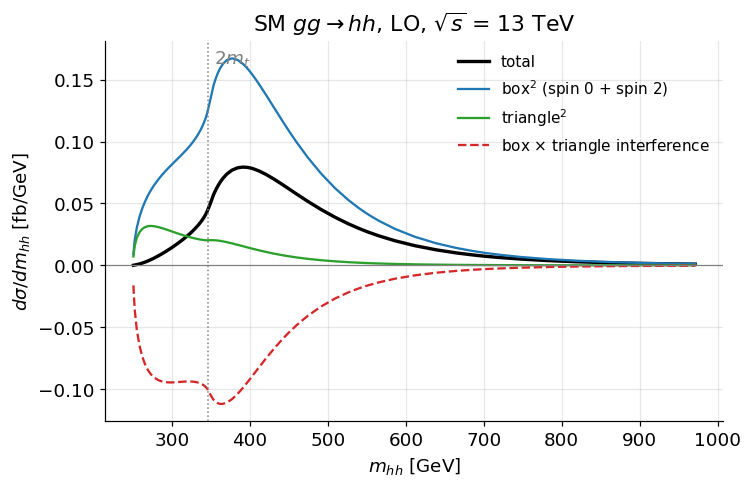

In [18]:
def plot_sm_anatomy(res):
    m, d = res["mhh"], res["dist"]
    sel = m < 1000
    fig, ax = plt.subplots()
    ax.plot(m[sel], res["dsig"][sel], "k-", lw=2.2, label="total")
    ax.plot(m[sel], (d["box (spin 0)"] + d["box (spin 2)"])[sel], "-", c="tab:blue", label="box$^2$ (spin 0 + spin 2)")
    ax.plot(m[sel], d["triangle h"][sel], "-", c="tab:green", label="triangle$^2$")
    ax.plot(m[sel], d["interf. box x tri h"][sel], "--", c="tab:red", label="box $\\times$ triangle interference")
    ax.axhline(0, c="grey", lw=0.8)
    ax.axvline(2 * SM["mt"], c="grey", ls=":", lw=1)
    ax.text(2 * SM["mt"] + 8, ax.get_ylim()[1] * 0.9, "$2m_t$", color="grey")
    ax.set_xlabel("$m_{hh}$ [GeV]"); ax.set_ylabel("$d\\sigma/dm_{hh}$ [fb/GeV]")
    ax.set_title(f"SM $gg\\to hh$, LO, $\\sqrt{{s}}$ = {COLLIDER['sqrts']/1000:.0f} TeV")
    ax.legend(fontsize=10)
    plt.tight_layout(); plt.show()

plot_sm_anatomy(res_SM)

**Interpretation.** The box dominates and peaks just above $2m_t$, where the top quarks in the loop can go
on shell and the form factors develop imaginary parts. The triangle is concentrated at low $m_{hh}$ because
of the $1/(\hat s-m_h^2)$ propagator. Their interference is negative over the whole range and largest near
threshold, which suppresses the spectrum below about 350 GeV. This low-$m_{hh}$ region is what carries the
sensitivity to $\kappa_\lambda$.

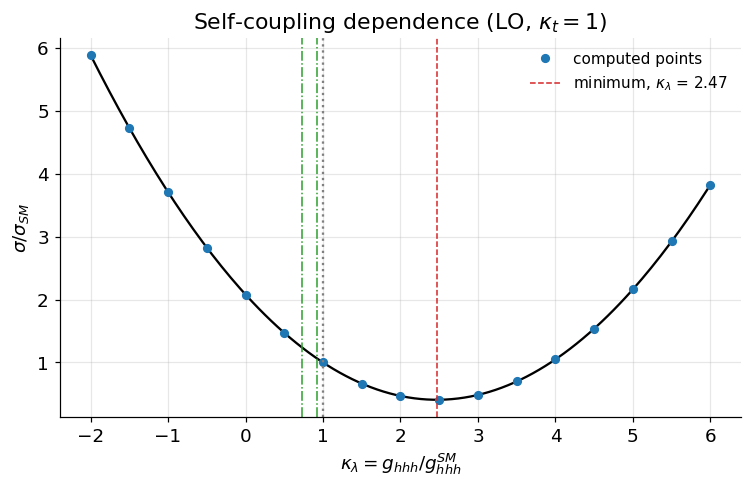

In [19]:
def plot_kl_scan():
    fig, ax = plt.subplots()
    k = np.linspace(kl_values[0], kl_values[-1], 200)
    ax.plot(k, np.polyval([C2, C1, C0_], k) / res_SM["sigma"], "k-")
    ax.plot(kl_values, sig_kl / res_SM["sigma"], "o", c="tab:blue", ms=5, label="computed points")
    ax.axvline(1, c="grey", ls=":"); ax.axvline(kl_min, c="tab:red", ls="--", lw=1,
                                                label=f"minimum, $\\kappa_\\lambda$ = {kl_min:.2f}")
    for p in BENCHMARKS:
        ax.axvline(a2hdm_couplings(p)["kappa_lambda"], c="tab:green", ls="-.", lw=1)
    ax.set_xlabel("$\\kappa_\\lambda = g_{hhh}/g_{hhh}^{SM}$"); ax.set_ylabel("$\\sigma/\\sigma_{SM}$")
    ax.set_title("Self-coupling dependence (LO, $\\kappa_t=1$)"); ax.legend(fontsize=10)
    plt.tight_layout(); plt.show()

plot_kl_scan()

**Interpretation.** The parabola encodes the triangle² ($\propto\kappa_\lambda^2$), interference ($\propto\kappa_\lambda$) and
box² (constant) pieces. The minimum near $\kappa_\lambda\approx2.4$ is where destructive interference is maximal.
Dash-dotted green lines mark the effective $\kappa_\lambda$ of the A2HDM benchmarks. For BP1 the full model also
changes $y_t^h$, so it does not sit exactly on this $\kappa_t=1$ curve.

### 10.2 SM versus A2HDM: $m_{hh}$ and Higgs transverse momentum
The $p_{T,h}$ distribution is obtained from the same quadrature. For every $m_{hh}$ node the box form factors
are interpolated in $\cos^2\theta$ by a cubic spline onto a fine angular grid, and each point is binned in
$p_T = \tfrac12\sqrt{\hat s}\,\beta\sin\theta$. The resonant propagators are evaluated exactly at every point.

In [20]:
def pt_distribution(res, model, bins=np.linspace(0, 600, 41), n_fine=400):
    """d sigma/d pT [fb/GeV] using the m_hh quadrature of `res` and a fine cos-theta grid."""
    c_f = (np.arange(n_fine) + 0.5) / n_fine
    hist = np.zeros(len(bins) - 1)
    for mhh, wm in zip(res["mhh"], res["w"]):
        s, mh = mhh**2, SM["mh"]
        beta = np.sqrt(1 - 4 * mh**2 / s)
        Fb, Gb = box_ff(mhh)
        spl = lambda f: CubicSpline(COS_NODES**2, f.real)(c_f**2) + 1j * CubicSpline(COS_NODES**2, f.imag)(c_f**2)
        Fb_f, Gb_f = spl(Fb), spl(Gb)
        pcs = amplitude_pieces(mhh, model)
        tri = sum(v[0] for v in pcs["tri"].values())        # triangle pieces do not depend on the angle
        yt2 = model["yt_h"] ** 2
        M2 = np.abs(tri + yt2 * Fb_f) ** 2 + np.abs(yt2 * Gb_f) ** 2
        mu = COLLIDER["mu_over_mhh"] * mhh
        pref = SM["GF"] ** 2 * PDF.alphas(mu) ** 2 / (512 * (2 * np.pi) ** 3) * (s * beta / 2) * 2
        lum = 2 * mhh / COLLIDER["sqrts"] ** 2 * PDF.lumi_gg(s / COLLIDER["sqrts"] ** 2, mu)
        wgt = pref * lum * GEV2_TO_FB * wm * M2 / n_fine
        pT = 0.5 * mhh * beta * np.sqrt(1 - c_f**2)
        hist += np.histogram(pT, bins=bins, weights=wgt)[0]
    return bins, hist / np.diff(bins)

MODELS = {"SM": sm_model()}
MODELS.update({p["name"]: a2hdm_model(p) for p in BENCHMARKS if p["name"] in RESULTS})
PT = {name: pt_distribution(RESULTS[name], MODELS[name]) for name in RESULTS}
for name, (b, h) in PT.items():
    ALL_CHECKS.append(check(f"pT histogram integrates to sigma ({name})",
                            abs(np.sum(h * np.diff(b)) / RESULTS[name]["sigma"] - 1) < 0.01,
                            f"(pT < 600 GeV captures {np.sum(h*np.diff(b))/RESULTS[name]['sigma']:.4f})"))

[PASS] pT histogram integrates to sigma (SM) (pT < 600 GeV captures 0.9987)
[PASS] pT histogram integrates to sigma (BP1 non-res.) (pT < 600 GeV captures 0.9990)
[PASS] pT histogram integrates to sigma (BP2 resonant) (pT < 600 GeV captures 0.9997)


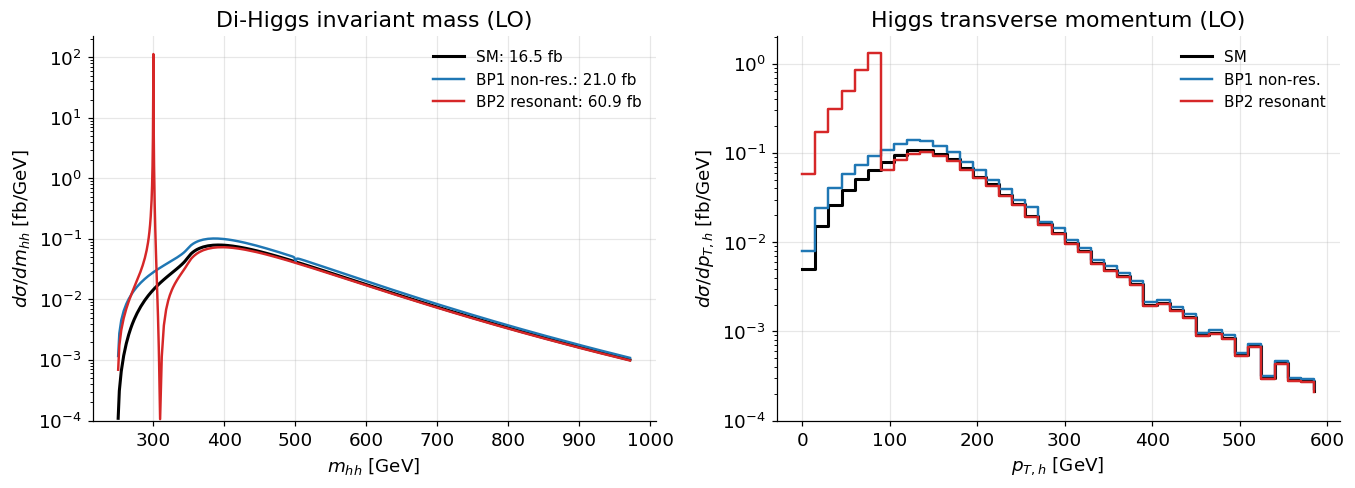

In [21]:
COLORS = {"SM": "k", BP1["name"]: "tab:blue", BP2["name"]: "tab:red"}

def plot_comparison():
    colors = COLORS
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
    for name, r in RESULTS.items():
        sel = r["mhh"] < 1000
        axes[0].plot(r["mhh"][sel], r["dsig"][sel], "-", c=colors.get(name), lw=2 if name == "SM" else 1.6,
                     label=f"{name}: {r['sigma']:.1f} fb")
        b, h = PT[name]
        axes[1].step(b[:-1], h, where="post", c=colors.get(name), lw=2 if name == "SM" else 1.6, label=name)
    axes[0].set_yscale("log"); axes[0].set_ylim(1e-4, None)
    axes[1].set_yscale("log"); axes[1].set_ylim(1e-4, None)
    axes[0].set_xlabel("$m_{hh}$ [GeV]"); axes[0].set_ylabel("$d\\sigma/dm_{hh}$ [fb/GeV]")
    axes[1].set_xlabel("$p_{T,h}$ [GeV]"); axes[1].set_ylabel("$d\\sigma/dp_{T,h}$ [fb/GeV]")
    axes[0].set_title("Di-Higgs invariant mass (LO)"); axes[1].set_title("Higgs transverse momentum (LO)")
    for a in axes: a.legend(fontsize=10)
    plt.tight_layout(); plt.show()

plot_comparison()

**Interpretation.** BP1 raises the rate without moving the peak. Its reduced $\kappa_\lambda$ weakens the
destructive triangle–box interference, so the spectrum grows most below about 400 GeV. The small step at
$m_{hh}=500$ GeV is the $H$ resonance produced only through its tiny $b$-quark loop ($y_t^H=0$ here).
BP2 adds a narrow peak at $m_{hh}=m_H=300$ GeV. Because the $H$ propagator changes sign across the peak, its
interference with the continuum raises the spectrum just below $m_H$ and digs a dip just above it. Whether the
excess sits below or above the peak follows the sign of $y_t^H g_{Hhh}$, and this peak–dip pattern is a
characteristic signature. In $p_T$ the resonance piles up below the Jacobian edge at
$p_T^{\max}=\tfrac12\sqrt{m_H^2-4m_h^2}\approx 83$ GeV.

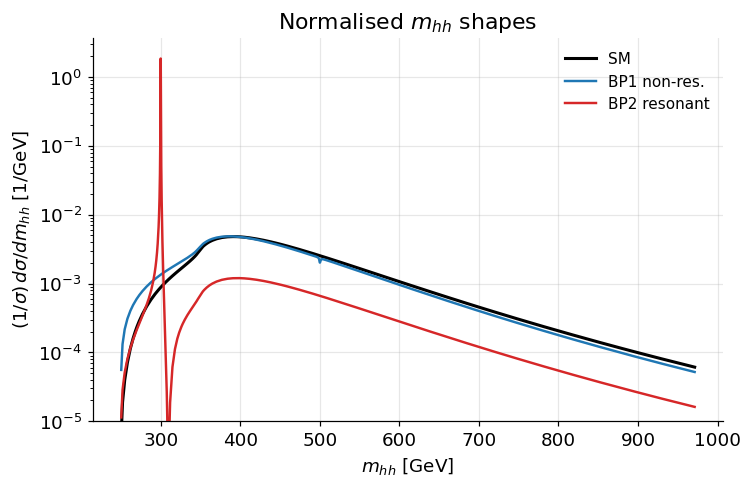

In [22]:
def plot_shapes():
    fig, ax = plt.subplots()
    for name, r in RESULTS.items():
        sel = r["mhh"] < 1000
        ax.plot(r["mhh"][sel], r["dsig"][sel] / r["sigma"], c=COLORS.get(name), lw=2 if name == "SM" else 1.6, label=name)
    ax.set_yscale("log"); ax.set_ylim(1e-5, None)
    ax.set_xlabel("$m_{hh}$ [GeV]"); ax.set_ylabel("$(1/\\sigma)\\, d\\sigma/dm_{hh}$ [1/GeV]")
    ax.set_title("Normalised $m_{hh}$ shapes"); ax.legend(fontsize=10)
    plt.tight_layout(); plt.show()

plot_shapes()

**Interpretation.** Normalising removes the rate and isolates the shape change; the log scale keeps the
continuum visible next to the BP2 peak. A shift of the non-resonant
spectrum toward low $m_{hh}$ indicates a modified triangle–box balance, meaning $\kappa_\lambda$ or $\kappa_t$.
A localised excess indicates an s-channel resonance.

## 11. Results summary and reproducibility

In [23]:
def summary_table():
    rows = []
    for name, r in RESULTS.items():
        if name == "SM":
            rows.append(dict(benchmark="SM", mH=np.nan, sin_alpha=0.0, zeta_u=np.nan, yt_h=1.0, kappa_lambda=1.0,
                             yt_H=np.nan, g_Hhh=np.nan, Gamma_H=np.nan, sigma_fb=r["sigma"], ratio=1.0))
            continue
        p = next(b for b in BENCHMARKS if b["name"] == name)
        C = a2hdm_couplings(p)
        rows.append(dict(benchmark=name, mH=p["mH"], sin_alpha=p["sin_alpha"], zeta_u=p["zeta_u"], yt_h=C["yt_h"],
                         kappa_lambda=C["kappa_lambda"], yt_H=C["yt_H"], g_Hhh=C["g_Hhh"],
                         Gamma_H=sum(width_H(p).values()), sigma_fb=r["sigma"], ratio=r["sigma"] / res_SM["sigma"]))
    return pd.DataFrame(rows).set_index("benchmark")

SUMMARY = summary_table()
display(SUMMARY.round(4))

,mH,sin_alpha,zeta_u,yt_h,kappa_lambda,yt_H,g_Hhh,Gamma_H,sigma_fb,ratio
benchmark,,,,,,,,,,
SM,NaN,0.00,NaN,1.0000,1.0000,NaN,NaN,NaN,16.5137,1.0000
BP1 non-res.,500.0,-0.10,-0.1005,1.0050,0.7251,0.0000,251.1509,1.6063,20.9571,1.2691
BP2 resonant,300.0,-0.08,0.0400,0.9936,0.9180,0.1199,105.2788,0.2568,60.8945,3.6875


In [24]:
# Reproducibility: the whole calculation is deterministic (fixed quadratures, no random numbers).
# Clearing the cache and recomputing one A2HDM benchmark must give bit-identical results.
name_check = BP2["name"] if BP2["name"] in RESULTS else "SM"
model_check = MODELS[name_check]
_BOX_CACHE.clear()
again = cross_section(model_check, verbose=False)
ALL_CHECKS.append(check(f"reproducible after clearing the cache ({name_check})",
                        again["sigma"] == RESULTS[name_check]["sigma"],
                        f"{again['sigma']!r} vs {RESULTS[name_check]['sigma']!r}"))
ALL_CHECKS.append(check("all cross sections finite and positive",
                        all(np.isfinite(r["sigma"]) and r["sigma"] > 0 for r in RESULTS.values())))
print(f"\n{sum(ALL_CHECKS)}/{len(ALL_CHECKS)} validation checks passed")

[PASS] reproducible after clearing the cache (BP2 resonant) 60.89447240529008 vs 60.89447240529008
[PASS] all cross sections finite and positive 

21/21 validation checks passed


In [25]:
# Compact final comparison table: SM cross section, A2HDM cross section and the ratio.
final = pd.DataFrame([dict(benchmark=n, sigma_SM_fb=res_SM["sigma"], sigma_model_fb=r["sigma"],
                           ratio=r["sigma"] / res_SM["sigma"]) for n, r in RESULTS.items() if n != "SM"])
print(final.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

   benchmark  sigma_SM_fb  sigma_model_fb  ratio
BP1 non-res.       16.514          20.957  1.269
BP2 resonant       16.514          60.894  3.688


## 12. Scope, approximations and how to extend

**Exact in this notebook:** the LO $gg\to hh$ amplitude with full top-mass dependence, including both spin
states and all interference terms; the $b$-quark triangles; the gluon PDF convolution; the tree-level A2HDM
couplings; unitarity; and boundedness from below.

**Approximations, stated explicitly:**
1. **LO QCD.** NLO with full $m_t$ gives $K\approx1.7$ in the SM. Use ratios to the SM, and do not quote absolute rates.
2. **No $b$-quark box,** which is suppressed by $m_b^2/\hat s$. It would matter only for $\lvert\varsigma_d\rvert\gg10$.
3. **Fixed-width Breit–Wigner** for $H$, with LO partial widths. QCD corrections to $\Gamma(H\to b\bar b, gg)$ are neglected.
4. **No electroweak or one-loop scalar corrections** to $g_{hhh}$ and $g_{Hhh}$. These can be sizeable for heavy, non-degenerate scalars.
5. **Simplified phenomenological constraints.** Section 8.3 lists exactly what is and is not checked.
6. **Threshold window and spin-2 regularisation** (Section 4.2) control the numerics. The validation section quantifies them.

**To change the setup:** edit `SM`, `COLLIDER` or `NUM` and re-run everything. To study new points, call
`a2hdm_point(...)` and then `run_a2hdm(point)`. To use another PDF set, set `COLLIDER["pdf_set"]` to any
LHAPDF name. To add CP violation, extend `amplitude_pieces` with pseudoscalar box form factors and replace
`a2hdm_couplings` with the complex-$\varsigma$ couplings.

**Key references:** E. W. N. Glover and J. J. van der Bij, Nucl. Phys. B309 (1988) 282 · T. Plehn, M. Spira,
P. M. Zerwas, Nucl. Phys. B479 (1996) 46 [hep-ph/9603205] · S. Borowka et al., PRL 117 (2016) 012001
[1604.06447] and JHEP 10 (2016) 107 [1608.04798] · A. Pich and P. Tuzón, PRD 80 (2009) 091702 [0908.1554] ·
A. Celis, V. Ilisie, A. Pich, JHEP 07 (2013) 053 [1302.4022] · I. F. Ginzburg and I. P. Ivanov, PRD 72 (2005)
115010 [hep-ph/0508020] · H. E. Haber and D. O'Neil, PRD 83 (2011) 055017 [1011.6188] · M. Jung, A. Pich,
P. Tuzón, JHEP 11 (2010) 003 [1006.0470].